# 2.0 Which cost lines drive the deficits?

Once the board knows where the pressure is, the next question is **why**: has income failed to keep up
with costs, and which cost lines have grown fastest? This notebook compares income and cost growth by
sector, ranks the operating-expense lines by growth, tracks pay as a share of income, and compares the
cost mix of deficit and surplus trusts.

**Data:** NHS England Trust Accounts Consolidation (TAC), read from `analysis/data/` (exported from the
`nhs_gold` views by `python/reporting/export_for_analysis.py`). Annual, actuals only, £000s in the data and
£m on the charts. Operating surplus is the TAC SoCI line `SCI0140A` as each trust reported it. It is not
NHS England's adjusted financial performance measure, which excludes impairments and some transfers.

**Workforce caveat:** the TAC09 whole-time-equivalent (WTE) figures are incomplete for several trusts,
most visibly the ambulance trusts, where reported WTE is a small fraction of what the pay bill implies.
Cost per WTE would therefore mislead, so this notebook uses pay as a share of income instead.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

# Make analysis/nhs_analysis.py importable whether this runs from the repo root or this folder
ANALYSIS_DIR = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "nhs_analysis.py").exists()
                    or (p / "analysis" / "nhs_analysis.py").exists())
ANALYSIS_DIR = ANALYSIS_DIR if (ANALYSIS_DIR / "nhs_analysis.py").exists() else ANALYSIS_DIR / "analysis"
sys.path.insert(0, str(ANALYSIS_DIR))

import nhs_analysis as nhs

nhs.set_style()
pd.options.display.float_format = "{:,.1f}".format

In [2]:
ty = nhs.load_trust_year()
lines = nhs.load_expenditure_lines()
years = nhs.financial_years(ty)
first_year, latest_year = years[0], years[-1]
print(f"Comparing {first_year} with {latest_year}")

Comparing 2021/22 with 2023/24


## 2.1 Income growth against cost growth, by sector

Growth in combined income and combined expenditure between the first and latest year. Where the
expenditure bar is taller than the income bar, costs have grown faster than income.

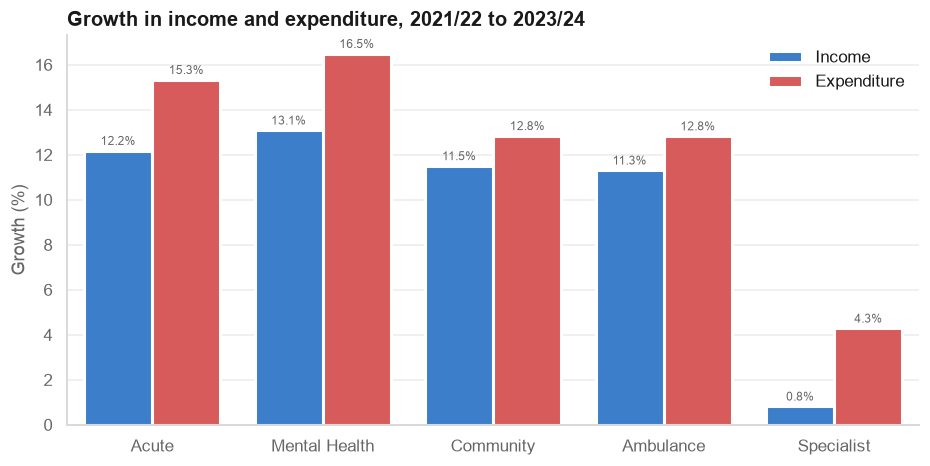

,Income,Expenditure,gap_pts
sector,,,
Acute,12.2,15.3,3.1
Mental Health,13.1,16.5,3.4
Community,11.5,12.8,1.3
Ambulance,11.3,12.8,1.5
Specialist,0.8,4.3,3.5


In [3]:
by_sector = (ty[ty.financial_year.isin([first_year, latest_year])]
             .groupby(["sector", "financial_year"], observed=True)
             [["total_income_000s", "total_expenditure_000s"]].sum())
growth = (by_sector.xs(latest_year, level="financial_year")
          / by_sector.xs(first_year, level="financial_year") - 1) * 100
growth = growth.rename(columns={"total_income_000s": "Income", "total_expenditure_000s": "Expenditure"})
growth_long = growth.reset_index().melt(id_vars="sector", var_name="measure", value_name="growth_pct")

fig, ax = plt.subplots(figsize=(10, 4.6))
sns.barplot(data=growth_long, x="sector", y="growth_pct", hue="measure", order=nhs.SECTOR_ORDER,
            palette={"Income": nhs.SURPLUS, "Expenditure": nhs.DEFICIT}, ax=ax,
            edgecolor="white", linewidth=2)
for container in ax.containers:
    ax.bar_label(container, fmt="%.1f%%", fontsize=8, padding=2, color=nhs.TEXT_SECONDARY)
ax.set(title=f"Growth in income and expenditure, {first_year} to {latest_year}",
       xlabel=None, ylabel="Growth (%)")
ax.legend(title=None)
plt.show()

growth.assign(gap_pts=lambda d: d.Expenditure - d.Income)

## 2.2 Which expense lines grew the most?

Every operating-expense line (TAC08) added up across all trusts, ranked by the increase in pounds between
the first and latest year. Bars show £m; the label gives the percentage growth.

Impairments are non-cash write-downs of buildings and equipment, usually after a revaluation. They push
a trust's reported operating result into deficit without any cash leaving the trust, which is why NHS
England's own performance measure excludes them. Read their growth separately from pay and drugs.

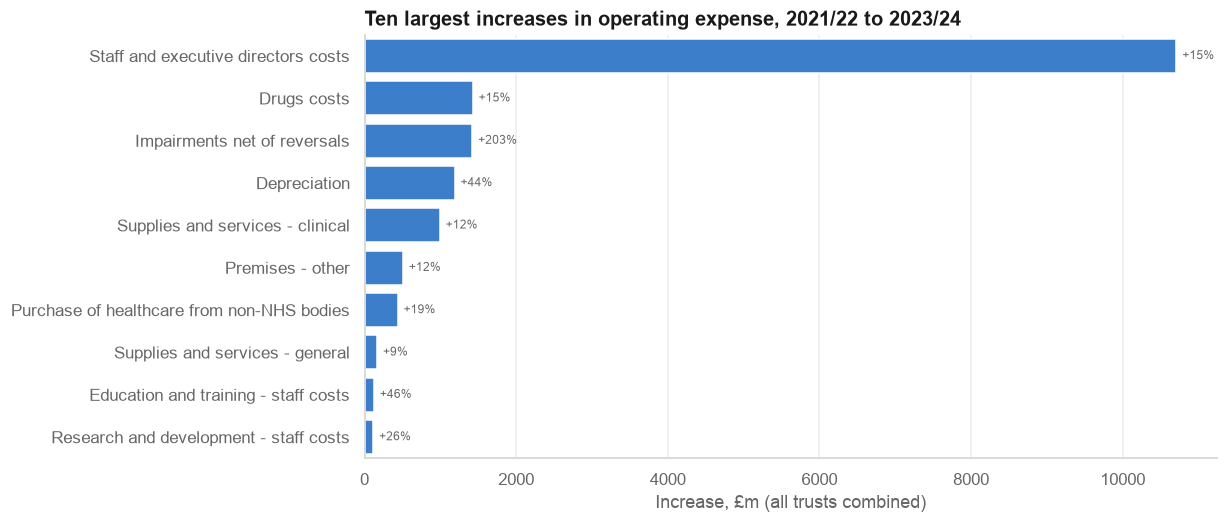

financial_year,line_item,increase_m,growth_pct
0,Staff and executive directors costs,"10,707.9",15.1
1,Drugs costs,"1,426.1",15.3
2,Impairments net of reversals,"1,420.5",202.8
3,Depreciation,"1,187.9",43.9
4,Supplies and services - clinical,992.1,11.8
5,Premises - other,507.0,12.2
6,Purchase of healthcare from non-NHS bodies,436.3,18.7
7,Supplies and services - general,164.9,9.0
8,Education and training - staff costs,123.6,45.7
9,Research and development - staff costs,113.5,26.1


In [4]:
nat = (lines[lines.financial_year.isin([first_year, latest_year])]
       .groupby(["line_item", "financial_year"])["amount_000s"].sum()
       .unstack("financial_year"))
nat["increase_m"] = nhs.to_m(nat[latest_year] - nat[first_year])
nat["growth_pct"] = (nat[latest_year] / nat[first_year] - 1) * 100
top = nat.sort_values("increase_m", ascending=False).head(10).reset_index()

fig, ax = plt.subplots(figsize=(10, 5))
sns.barplot(data=top, y="line_item", x="increase_m", color=nhs.SECTOR_COLOURS["Acute"], ax=ax)
for bar, pct in zip(ax.patches, top.growth_pct):
    ax.text(bar.get_width(), bar.get_y() + bar.get_height() / 2, f"  +{pct:.0f}%",
            va="center", fontsize=8, color=nhs.TEXT_SECONDARY)
ax.set(title=f"Ten largest increases in operating expense, {first_year} to {latest_year}",
       xlabel="Increase, £m (all trusts combined)", ylabel=None)
plt.show()

top[["line_item", "increase_m", "growth_pct"]]

## 2.3 Pay as a share of income

Staff are the largest cost in every sector. The point is the median trust in each sector and the bar
spans the middle half of trusts (25th to 75th percentile).

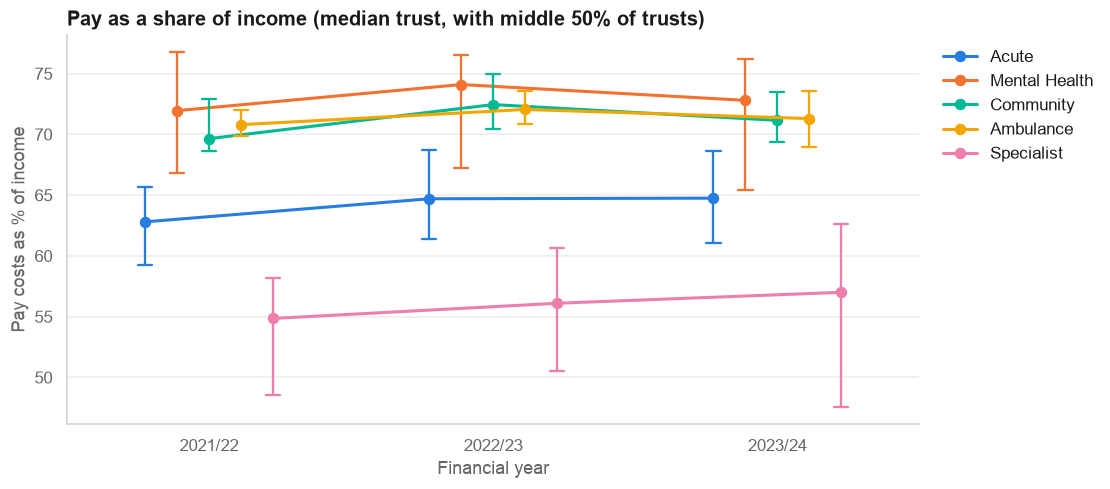

financial_year,2021/22,2022/23,2023/24
sector,,,
Acute,62.8,64.7,64.8
Mental Health,71.9,74.1,72.8
Community,69.7,72.4,71.2
Ambulance,70.8,72.0,71.3
Specialist,54.9,56.1,57.0


In [5]:
fig, ax = plt.subplots(figsize=(10, 4.6))
sns.pointplot(data=ty, x="financial_year", y="pay_pct_income", hue="sector",
              hue_order=nhs.SECTOR_ORDER, palette=nhs.SECTOR_COLOURS,
              estimator=np.median, errorbar=("pi", 50), dodge=0.45, markersize=6,
              linewidth=2, capsize=0.05, err_kws={"linewidth": 1.5}, ax=ax)
ax.set(title="Pay as a share of income (median trust, with middle 50% of trusts)",
       xlabel="Financial year", ylabel="Pay costs as % of income")
ax.legend(title=None, loc="upper left", bbox_to_anchor=(1.01, 1.0))
plt.show()

ty.pivot_table(index="sector", columns="financial_year", values="pay_pct_income",
               aggfunc="median", observed=True)

## 2.4 Cost mix of deficit trusts against surplus trusts

In the latest year, each cost group as a share of the trust's total operating expenditure. The median
trust in each group is shown. If deficit trusts spend a noticeably larger share on one line, that line
is a candidate driver.

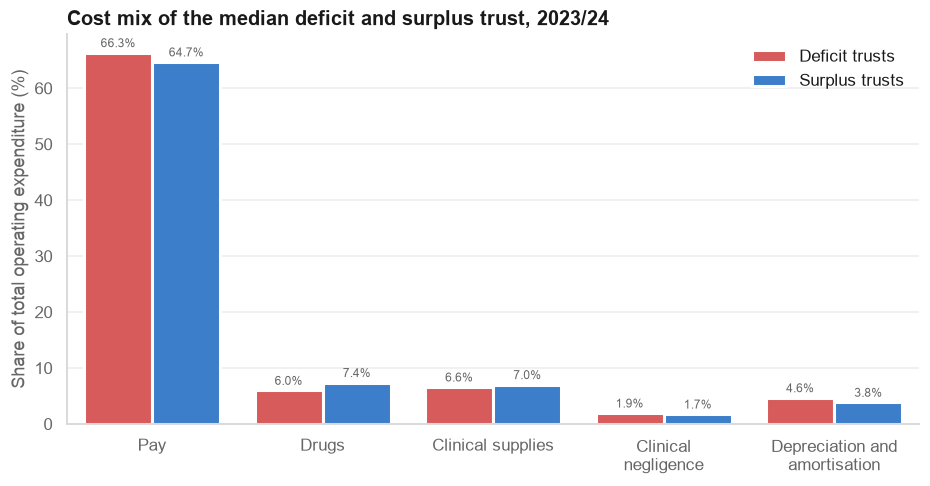

status
Deficit trusts    124
Surplus trusts     82


In [6]:
latest = ty[ty.financial_year == latest_year].copy()
mix_cols = {
    "pay_000s": "Pay",
    "drugs_cost_000s": "Drugs",
    "clinical_supplies_000s": "Clinical supplies",
    "clinical_negligence_000s": "Clinical\nnegligence",
    "depreciation_amort_000s": "Depreciation and\namortisation",
}
for col in mix_cols:
    latest[mix_cols[col]] = latest[col] / latest["total_expenditure_000s"] * 100
latest["status"] = np.where(latest.is_deficit == 1, "Deficit trusts", "Surplus trusts")
mix = (latest.groupby("status")[list(mix_cols.values())].median()
             .reset_index().melt(id_vars="status", var_name="cost_line", value_name="share_pct"))

fig, ax = plt.subplots(figsize=(10, 4.6))
sns.barplot(data=mix, x="cost_line", y="share_pct", hue="status",
            palette={"Deficit trusts": nhs.DEFICIT, "Surplus trusts": nhs.SURPLUS}, ax=ax,
            edgecolor="white", linewidth=2)
for container in ax.containers:
    ax.bar_label(container, fmt="%.1f%%", fontsize=8, padding=2, color=nhs.TEXT_SECONDARY)
ax.set(title=f"Cost mix of the median deficit and surplus trust, {latest_year}",
       xlabel=None, ylabel="Share of total operating expenditure (%)")
ax.legend(title=None)
plt.show()

print(latest.status.value_counts().to_string())